In [77]:
import spatialdata as sd
import decoupler as dc
from spatialdata_io import xenium

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

sc.set_figure_params(figsize=(16, 16))

%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
%config InlineBackend.figure_format='retina'

In [78]:
Sample_895=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_895.h5ad")
Sample_894=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_894.h5ad")
Sample_898=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_898.h5ad")


Sample_896=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_896.h5ad")
Sample_897=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_897.h5ad")
Sample_18=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_18.h5ad")


Sample_886=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_886.h5ad")
Sample_890=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_890.h5ad")
Sample_891=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_891.h5ad")


Sample_4=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_4.h5ad")
Sample_5=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_5.h5ad")
Sample_3=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_3.h5ad")


Sample_706=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_706.h5ad")
Sample_707=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_707.h5ad")
Sample_709T=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_709T.h5ad")

In [3]:
Sample_895.X = Sample_895.X.toarray()

In [81]:
Dp140_895 = Sample_895[:, 'Dystrophin_Exon56_62'].X - Sample_895[:, 'Dystrophin_Exon45_49'].X
Dp140_895_dense = Dp140_895.toarray().flatten() if hasattr(Dp140_895, 'toarray') else Dp140_895.flatten()
Dp140_895_dense[Dp140_895_dense < 0] = 0
Dp140_895_dense = sp.csr_matrix(Dp140_895_dense)

In [82]:
import pandas as pd

# Add a new row to var for the new feature (you can adjust the name of the feature as needed)
new_feature_name = "Dp140"  # Adjust this to the name of your new feature
new_feature_metadata = pd.DataFrame(index=[new_feature_name], columns=Sample_895.var.columns)

# Add this new feature metadata to the existing var
updated_var = pd.concat([Sample_895.var, new_feature_metadata])

/tmp/ipykernel_3442582/3879524929.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_var = pd.concat([Sample_895.var, new_feature_metadata])
/tmp/ipykernel_3442582/3879524929.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_var = pd.concat([Sample_895.var, new_feature_metadata])


In [86]:
import anndata as ad

# Create a new AnnData object with the updated expression matrix
updated_X = sp.hstack([Sample_895.X, Dp140_895_dense.T])
new_Sample_895 = ad.AnnData(X=updated_X, obs=Sample_895.obs, var=updated_var)

In [87]:
new_Sample_895.obsm=Sample_895.obsm

In [88]:
new_Sample_895.X = new_Sample_895.X.toarray()

In [89]:
sc.pp.normalize_total(new_Sample_895, inplace=True)
sc.pp.log1p(new_Sample_895)
sc.pp.scale(new_Sample_895)

In [90]:
new_Sample_895.var_names_make_unique()

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  df[key] = c


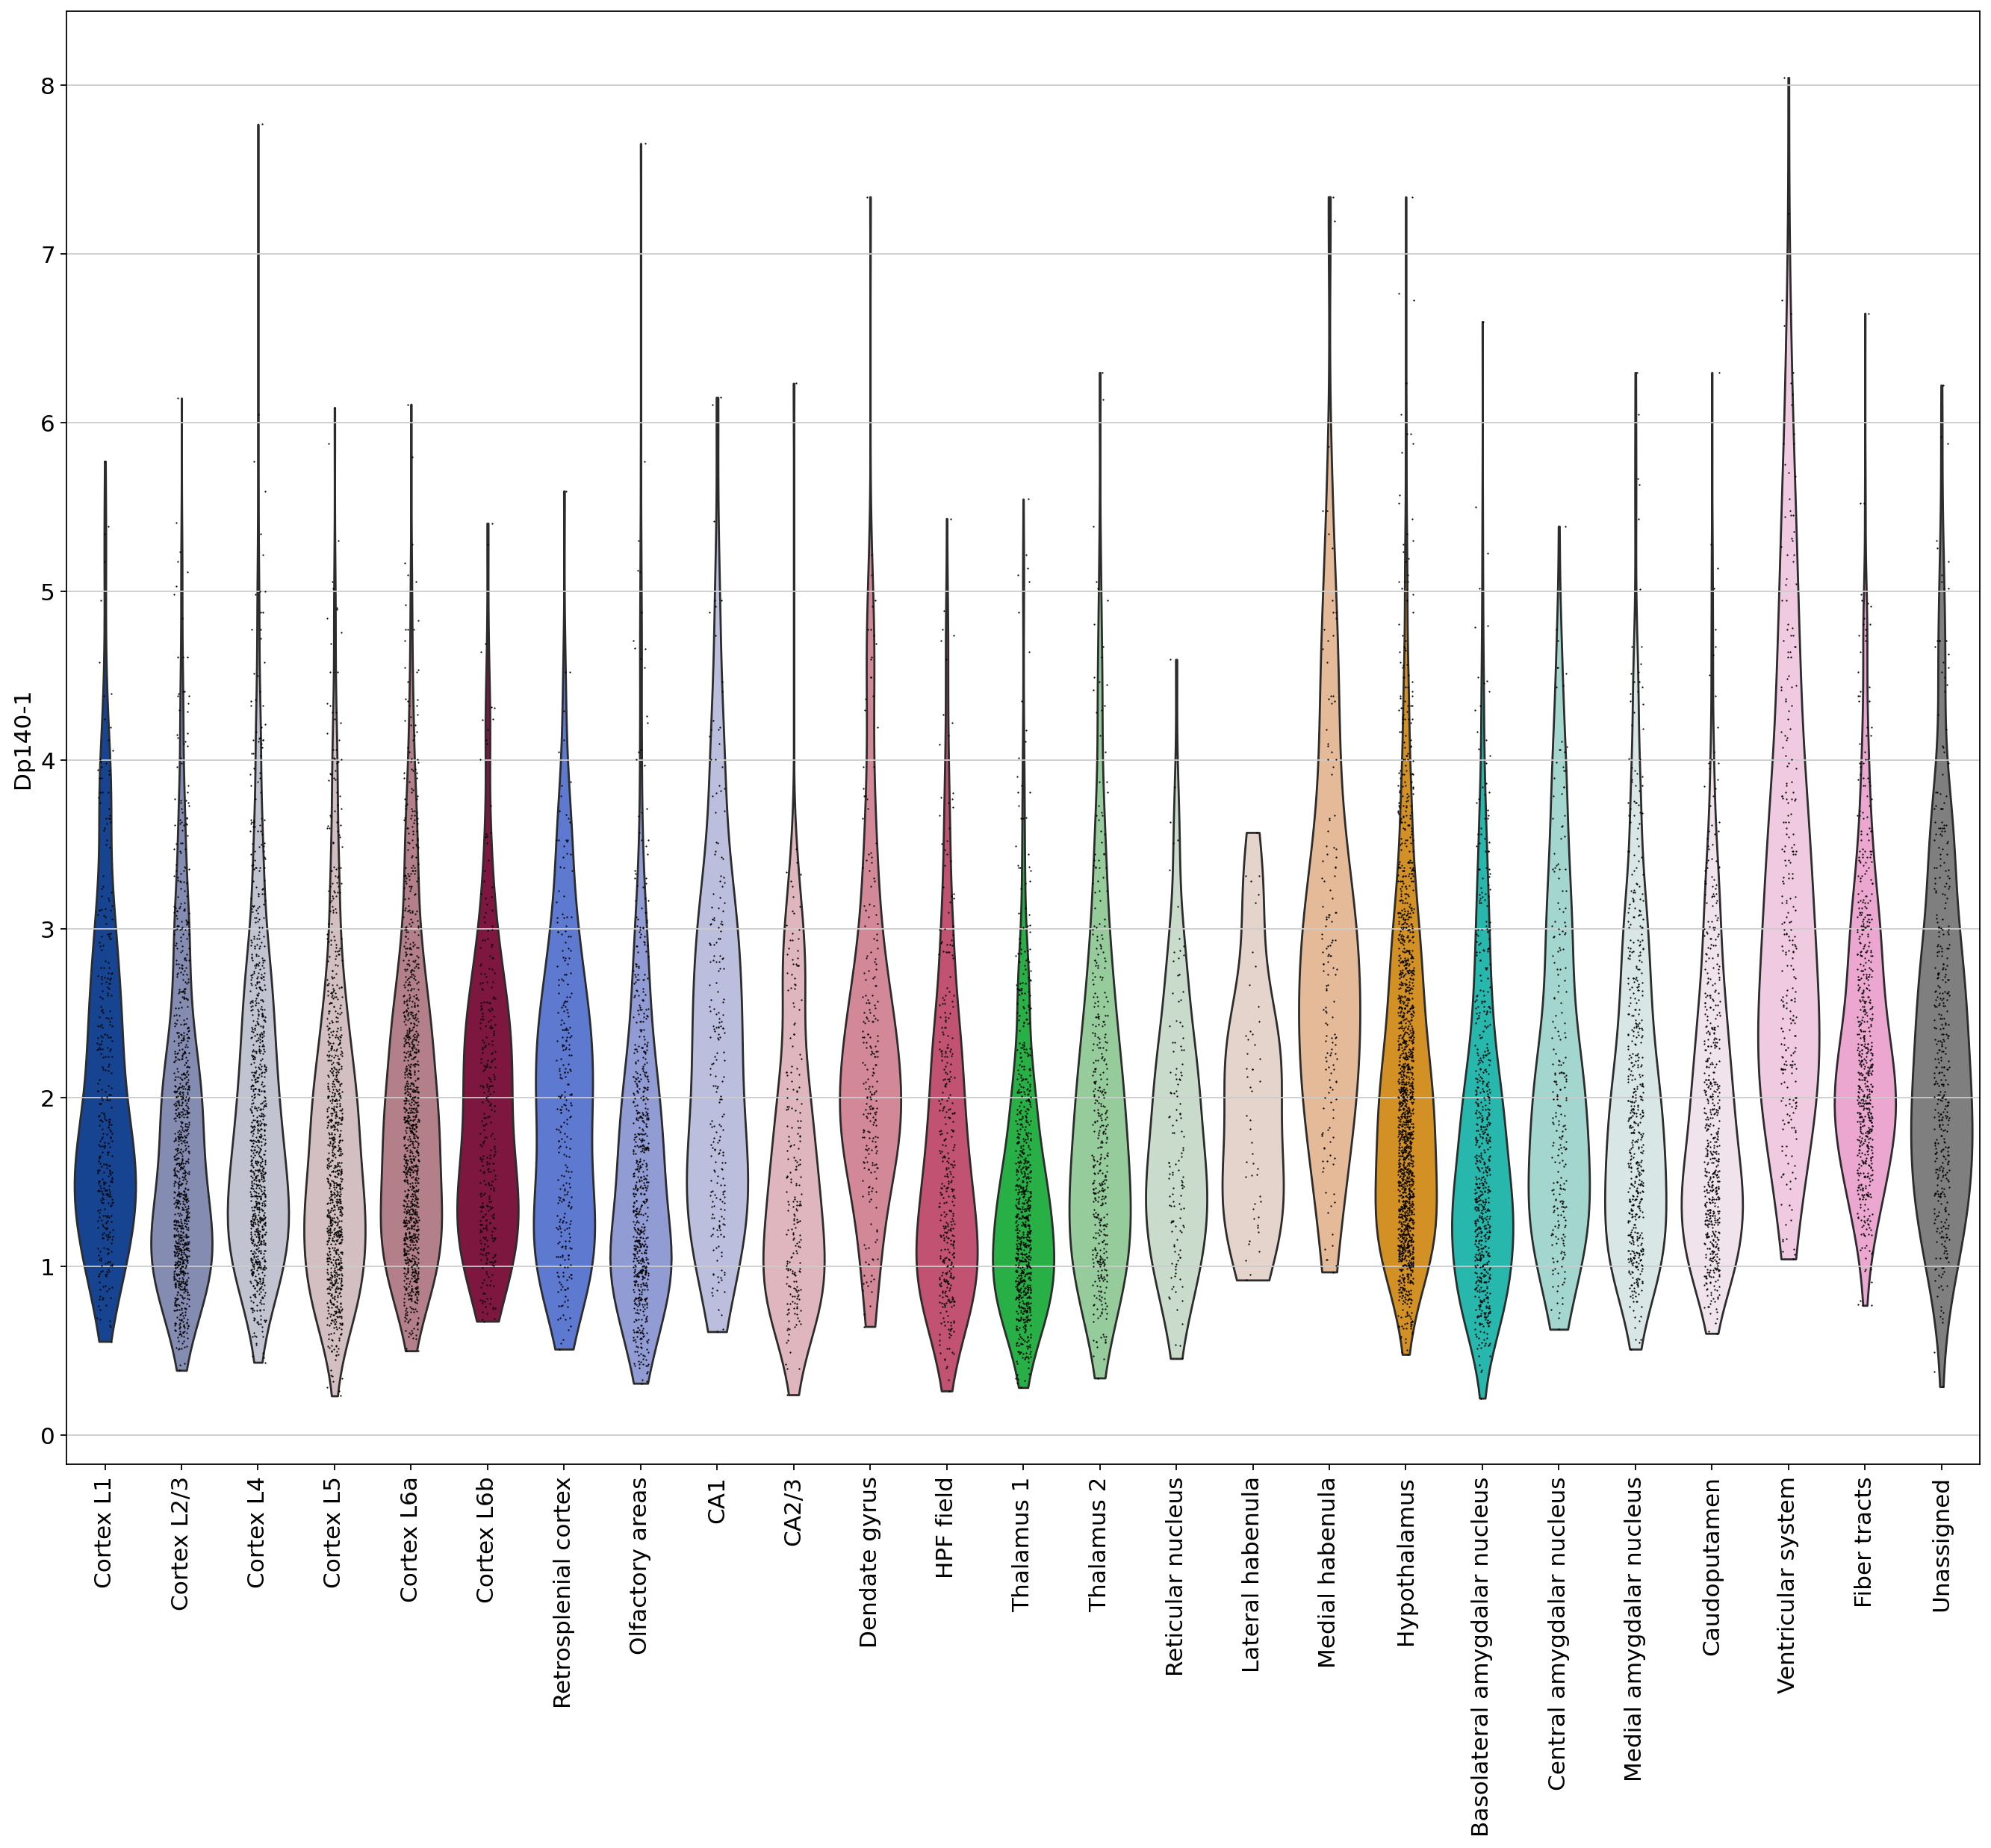

In [91]:
sc.pl.violin(new_Sample_895[new_Sample_895.X[:, new_Sample_895.var_names == "Dp140-1"].flatten() > 0, :],keys="Dp140-1",groupby="Region",rotation=90)

In [ ]:
sq.pl.spatial_scatter(
    new_Sample_895,
    library_id="spatial",
    color=["Dp140-1"],
    shape=None,
    size=1,
    img=False,
)